In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os, sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

from superres_dust.datasets import SRDDataModule
from superres_dust.models import Model
from superres_dust.utils.loss_functions import get_loss
from animation_fwhm_slider_jupyter import create_simple_jupyter_animation

## Load Data

In [4]:
config = {
    "debug": False,
    "num_workers": 4,
    "batch_size": 1,
    "dir": os.path.join(WDIR, "data")
}

datamodule = SRDDataModule(config)
datamodule.prepare_data()
train_loader = datamodule.train_dataloader()
val_loader = datamodule.val_dataloader()

for imgs, resols in train_loader:
    print(imgs.shape)
    print(resols.shape)
    break

for imgs, resols in val_loader:
    print(imgs.shape)
    print(resols.shape)
    break

Loading preprocessed data splits...


torch.Size([1, 7, 1, 80, 80])
torch.Size([1])
torch.Size([1, 7, 1, 80, 80])
torch.Size([1])


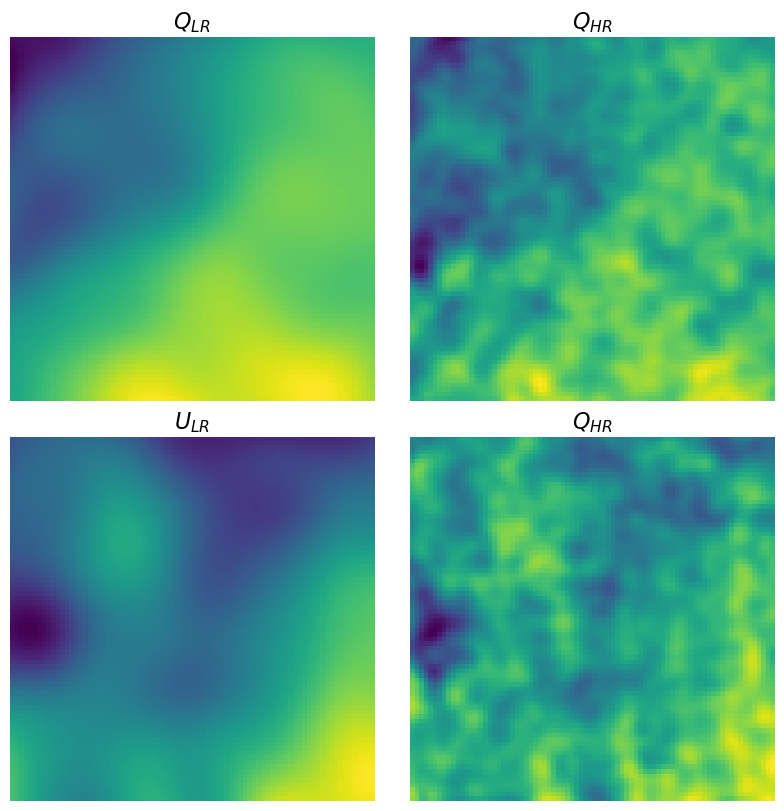

In [5]:
idx = 375
val_dataset = list(val_loader)
val_img, val_res = val_dataset[idx]

idx_order = [3, 5, 4, 6]
title_arr = [r"$Q_{LR}$", r"$Q_{HR}$", r"$U_{LR}$", r"$Q_{HR}$"]
fig, axes = plt.subplots(2, 2, figsize=(8, 8), constrained_layout=True)
for i in range(4):
    axes[i//2, i%2].imshow(val_img[0, idx_order[i], 0])
    axes[i//2, i%2].set_title(title_arr[i], fontsize=16)
    axes[i//2, i%2].axis('off')
plt.show()

## Load Saved Model Checkpoint

In [6]:
checkpoint_path = os.path.join(WDIR, "logs/wandb/run-20240628_123659-rs3xiln2/files/checkpoints/epoch_00209-val_loss_0.00366.ckpt")
ckpt = torch.load(checkpoint_path, map_location="cpu")
config_path = os.path.join(WDIR, "logs/wandb/run-20240628_123659-rs3xiln2/files/config.yaml")
with open(config_path, "r") as f:
    config = yaml.safe_load(f)
loss_config_path = os.path.join(WDIR, "configs/loss_functions.yaml")
with open(loss_config_path, "r") as f:
    loss_config = yaml.safe_load(f)
loss_func = get_loss(loss_config)
metric = config['metrics']['value']
extra_metric = config['extra_metrics']['value']
metrics_on_inputs = config['metrics_on_inputs']['value']
extra_metrics_on_inputs = config['extra_metrics_on_inputs']['value']
total_steps = config['total_steps']['value']

model = Model(config['config']['value'], loss_func, metric, extra_metric, metrics_on_inputs, extra_metrics_on_inputs, total_steps)
model.load_state_dict(ckpt['state_dict'])

model.eval()
pred_imgs = model(val_img, val_res).detach().cpu().numpy()

## Test Super-resolutin on validation dataset

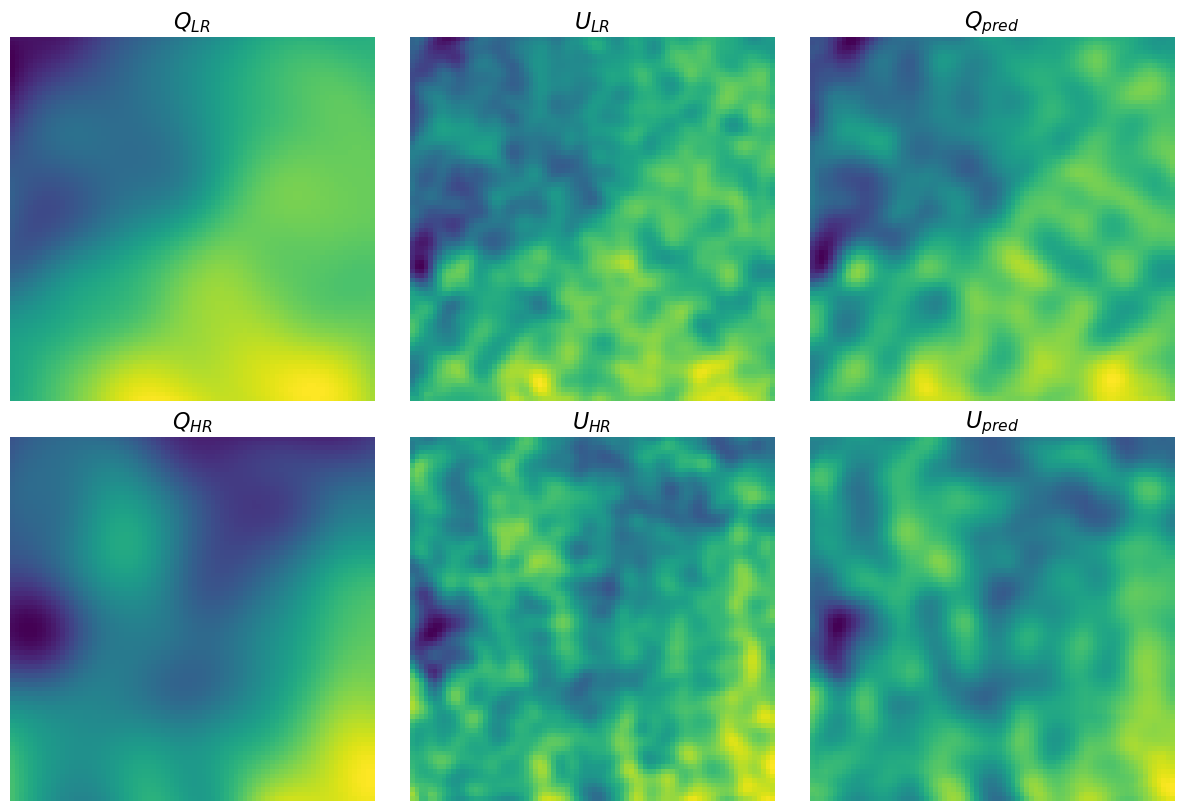

In [20]:
idx_order = [3, 5, 4, 6]
title_arr = [r"$Q_{LR}$", r"$U_{LR}$", r"$Q_{HR}$", r"$U_{HR}$", r'$Q_{pred}$', r'$U_{pred}$']
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for i in range(4):
    axes[i//2, i%2].imshow(val_img[0, idx_order[i], 0])
    axes[i//2, i%2].set_title(title_arr[i], fontsize=16)
    axes[i//2, i%2].axis('off')
axes[0,2].imshow(pred_imgs[0, 0, 0])
axes[1,2].imshow(pred_imgs[0, 1, 0])
axes[0,2].set_title(title_arr[4], fontsize=16)
axes[1,2].set_title(title_arr[5], fontsize=16)
axes[0,2].axis('off')
axes[1,2].axis('off')
plt.show()

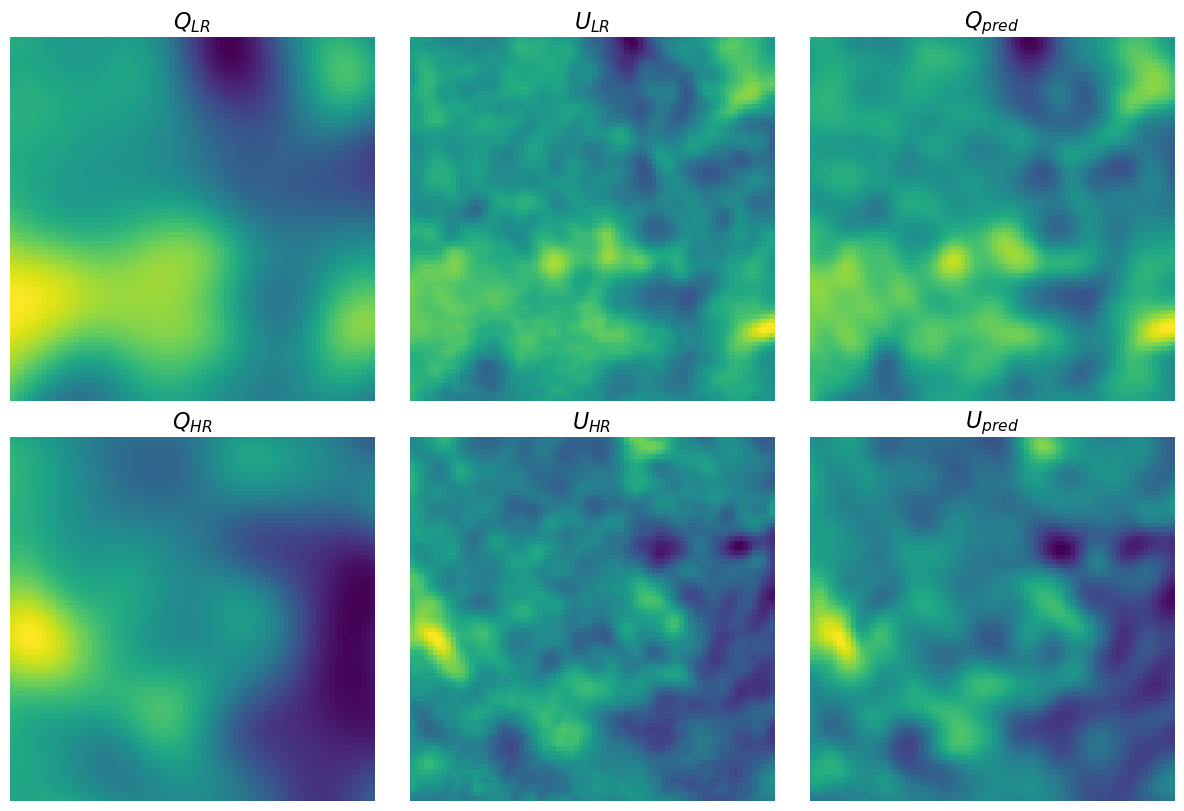

In [21]:
idx = 125  # Can change this index as needed
val_img, val_res = val_dataset[idx]

pred_imgs = model(val_img, val_res).detach().cpu().numpy()

idx_order = [3, 5, 4, 6]
title_arr = [r"$Q_{LR}$", r"$U_{LR}$", r"$Q_{HR}$", r"$U_{HR}$", r'$Q_{pred}$', r'$U_{pred}$']
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for i in range(4):
    axes[i//2, i%2].imshow(val_img[0, idx_order[i], 0])
    axes[i//2, i%2].set_title(title_arr[i], fontsize=16)
    axes[i//2, i%2].axis('off')
axes[0,2].imshow(pred_imgs[0, 0, 0])
axes[1,2].imshow(pred_imgs[0, 1, 0])
axes[0,2].set_title(title_arr[4], fontsize=16)
axes[1,2].set_title(title_arr[5], fontsize=16)
axes[0,2].axis('off')
axes[1,2].axis('off')
plt.show()

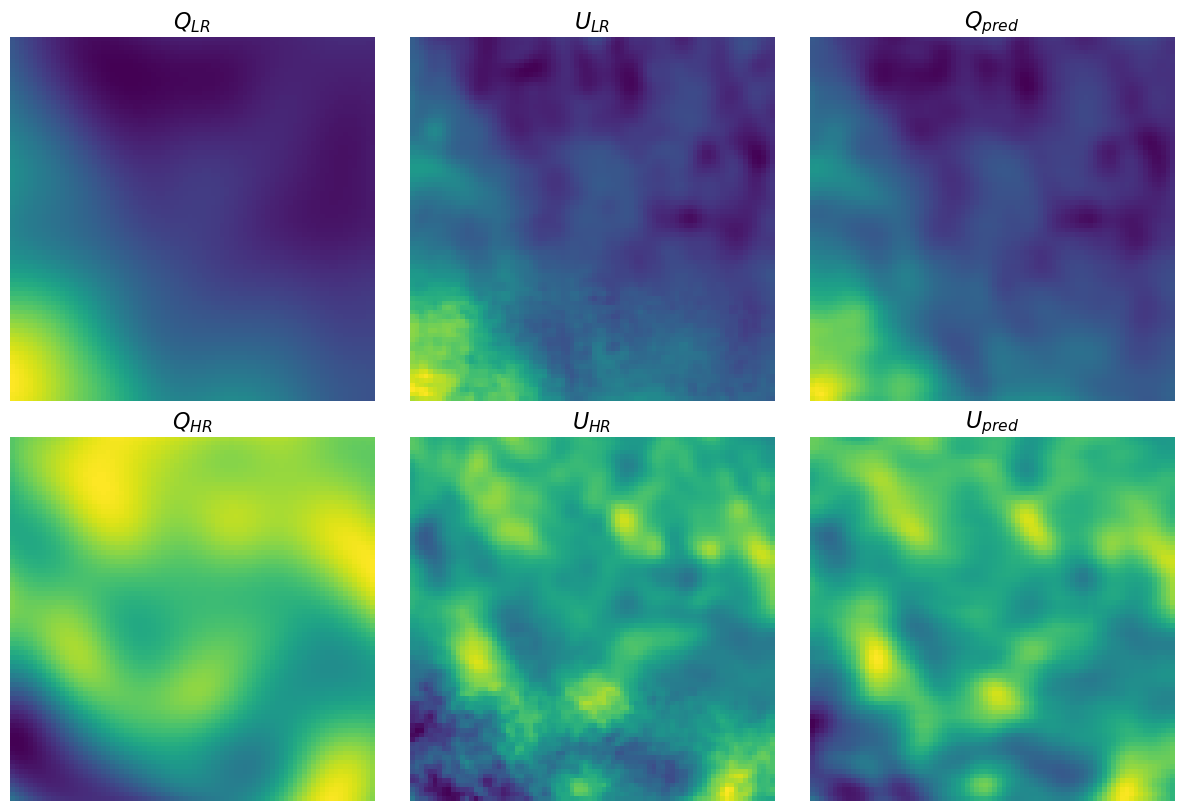

In [45]:
idx = 25  # Can change this index as needed
val_img, val_res = val_dataset[idx]

pred_imgs = model(val_img, val_res).detach().cpu().numpy()

idx_order = [3, 5, 4, 6]
title_arr = [r"$Q_{LR}$", r"$U_{LR}$", r"$Q_{HR}$", r"$U_{HR}$", r'$Q_{pred}$', r'$U_{pred}$']
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for i in range(4):
    axes[i//2, i%2].imshow(val_img[0, idx_order[i], 0])
    axes[i//2, i%2].set_title(title_arr[i], fontsize=16)
    axes[i//2, i%2].axis('off')
axes[0,2].imshow(pred_imgs[0, 0, 0])
axes[1,2].imshow(pred_imgs[0, 1, 0])
axes[0,2].set_title(title_arr[4], fontsize=16)
axes[1,2].set_title(title_arr[5], fontsize=16)
axes[0,2].axis('off')
axes[1,2].axis('off')
plt.show()